# Sprint 4 · Análisis post-mortem de errores del modelo campeón

Objetivo: identificar **en qué condiciones del mercado falla el pronóstico** del precio de bolsa sobre el conjunto de prueba (fuera de muestra), y cuánto del error total proviene de cada condición.

Requisitos, desde la raíz del repositorio:

```bash
python -m src.models.predict_model     # pronósticos y métricas en reports/metrics/
python -m src.visualization.visualize  # figuras en reports/figures/evaluacion/
```

Convenciones: error = pronóstico − real, en COP/kWh. Un error negativo es una **subestimación**. Todos los umbrales (hidrología, eventos extremos) se calculan con la partición de **entrenamiento**, nunca con la de prueba, para que los regímenes no se definan mirando el resultado que se evalúa.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

cwd = Path.cwd()
root = next((p for p in (cwd, *cwd.parents) if (p / 'config' / 'config.yaml').is_file()), None)
if root is None:
    raise FileNotFoundError('Abre el notebook dentro del repositorio.')
sys.path.insert(0, str(root))
from src.config import read_config_mapping
from src.data.preprocess import HOURLY_FILE
from src.features.build_features import METADATA_FILE
from src.models.predict_model import PREDICTIONS_FILE, SUMMARY_FILE, METRICS_FILE

config = read_config_mapping(root / 'config' / 'config.yaml')
paths, evaluation = config['paths'], config['evaluation']
metrics_dir = root / paths['reports']['metrics']
figures = root / paths['reports']['figures'] / evaluation['figures_subdir']
figures.mkdir(parents=True, exist_ok=True)
pd.set_option('display.float_format', '{:,.2f}'.format)

def export(fig, name):
    fig.savefig(figures / f'{name}.png', dpi=evaluation['dpi'], bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

predictions = pd.read_parquet(metrics_dir / PREDICTIONS_FILE)
summary = json.loads((metrics_dir / SUMMARY_FILE).read_text(encoding='utf-8'))
metadata = json.loads((root / paths['data']['processed'] / METADATA_FILE).read_text(encoding='utf-8'))
hourly = pd.read_parquet(root / paths['data']['interim'] / HOURLY_FILE).set_index('fecha')
train_end = pd.Timestamp(metadata['splits']['train']['end'])
train = hourly[hourly.index <= train_end]

frame = predictions.assign(
    error=predictions['champion'] - predictions['real'],
    error_naive=predictions['naive_24h'] - predictions['real'],
    hora=predictions['fecha_objetivo'].dt.hour,
)
frame['abs'] = frame['error'].abs()
frame['abs_naive'] = frame['error_naive'].abs()
display(summary['champion'], summary['test'])

C:\Users\Usuario\Documents\Especialización Inteligencia Artificial\Semestre 2\Deep Learning\WorkShops\WorkShop_1\deep-learning-ws\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'architecture': 'tcn',
 'params': {'learning_rate': 0.0002425547917876514,
  'lookback_steps': 96,
  'hidden_units': 256,
  'dropout': 0.014371618618746335},
 'lookback': 96,
 'val_cop': {'mae': 114.29273413178343, 'rmse': 146.16022748119258}}

{'windows': 249,
 'hours_evaluated': 5976,
 'horizon_h': 24,
 'first_forecast_hour': '2026-09-19T16:00:00-05:00',
 'last_forecast_hour': '2026-09-30T23:00:00-05:00'}

## 1. Contexto de la evaluación

Cada ventana de prueba pronostica las 24 h siguientes a su corte, así que cada hora del periodo se pronostica hasta 24 veces con distinta anticipación. Las métricas usan todas esas parejas (ventana, hora). La primera semana de la partición de prueba solo sirve como historia de entrada: las ventanas no cruzan la frontera con validación (Sprint 2).

In [2]:
table = pd.read_csv(metrics_dir / METRICS_FILE, index_col='modelo')
display(table)
print(f"Precio medio: entrenamiento {train['precio_bolsa'].mean():,.0f} | "
      f"prueba {frame.drop_duplicates('fecha_objetivo')['real'].mean():,.0f} COP/kWh")

,mae,rmse,mape_acotado,smape,acierto_direccional,mejora_mae_vs_naive_24h,mejora_mae_vs_naive_168h,mejora_mae_vs_ridge
modelo,,,,,,,,
champion,112.50,176.51,15.61,15.77,69.12,-0.06,0.13,0.59
naive_24h,106.38,161.60,15.67,15.66,55.57,0.00,0.17,0.61
naive_168h,128.92,179.18,18.76,20.37,67.14,-0.21,0.00,0.53
ridge,275.14,319.77,47.10,35.92,71.24,-1.59,-1.13,0.00


Precio medio: entrenamiento 744 | prueba 660 COP/kWh


## 2. Horas de punta frente a horas valle

Punta: horas `evaluation.peak_hours` (18 a 21 h, demanda máxima del SIN). Valle: 0 a 5 h (madrugada, demanda mínima). El resto son horas intermedias. Para cada régimen se reporta el MAE del campeón y de la persistencia de 24 h, el sesgo medio y la fracción del error absoluto total que aporta.

,horas,mae_campeon,mae_persistencia_24h,sesgo_campeon,fraccion_horas,fraccion_error
regimen,,,,,,
valle,1494,67.94,45.99,39.80,0.25,0.15
intermedia,3486,89.73,111.62,7.66,0.58,0.47
punta,996,259.04,178.63,-224.95,0.17,0.38


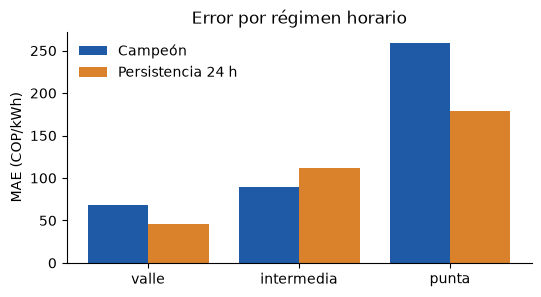

In [3]:
def regime_table(data, mask_or_labels):
    grouped = data.groupby(mask_or_labels)
    out = grouped.agg(
        horas=('abs', 'size'),
        mae_campeon=('abs', 'mean'),
        mae_persistencia_24h=('abs_naive', 'mean'),
        sesgo_campeon=('error', 'mean'),
    )
    out['fraccion_horas'] = out['horas'] / out['horas'].sum()
    out['fraccion_error'] = grouped['abs'].sum() / data['abs'].sum()
    return out

peak = evaluation['peak_hours']
frame['regimen'] = np.select(
    [frame['hora'].isin(peak), frame['hora'].between(0, 5)], ['punta', 'valle'], 'intermedia'
)
by_regime = regime_table(frame, 'regimen').loc[['valle', 'intermedia', 'punta']]
display(by_regime)

fig, ax = plt.subplots(figsize=(6, 3))
x = np.arange(len(by_regime))
ax.bar(x - 0.2, by_regime['mae_campeon'], 0.4, label='Campeón', color='#1f5aa6')
ax.bar(x + 0.2, by_regime['mae_persistencia_24h'], 0.4, label='Persistencia 24 h', color='#d9822b')
ax.set_xticks(x, by_regime.index)
ax.set_ylabel('MAE (COP/kWh)')
ax.set_title('Error por régimen horario')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
export(fig, 'mae_por_regimen_horario')

## 3. Hidrología y generación térmica

La base sí incluye `aportes_hidricos` (energía de los aportes al SIN, kWh/día) y la generación hidráulica y térmica. Ojo: en la tabla horaria cada dato diario aparece desde el día siguiente a su publicación (Sprint 2), así que el valor asociado a una hora objetivo refleja la hidrología del día anterior. Para un análisis post-mortem eso es una aproximación razonable de la condición del sistema.

**Baja hidrología**: aportes por debajo del percentil 25 del periodo de entrenamiento. **Alta participación térmica**: fracción térmica por encima de su percentil 75 de entrenamiento.

Umbral baja hidrología: 302 GWh/día
Umbral alta participación térmica: 29.3%


,horas,mae_campeon,mae_persistencia_24h,sesgo_campeon,fraccion_horas,fraccion_error
baja hidrología,,,,,,
False,576,102.89,58.94,10.66,0.10,0.09
True,5400,113.53,111.44,-26.67,0.90,0.91


,horas,mae_campeon,mae_persistencia_24h,sesgo_campeon,fraccion_horas,fraccion_error
alta participación térmica,,,,,,
True,5976,112.50,106.38,-23.07,1.00,1.00


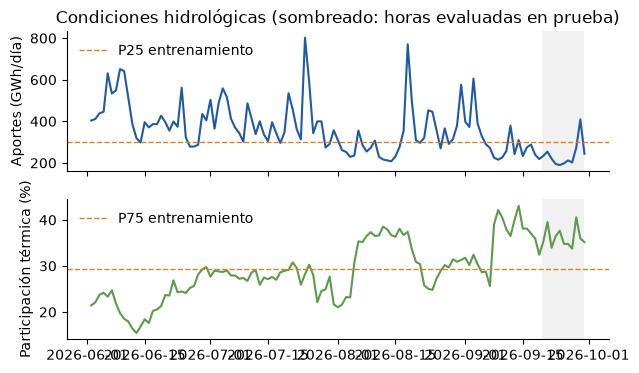

In [4]:
thermal_share = hourly['generacion_real_termica'] / (
    hourly['generacion_real_termica'] + hourly['generacion_real_hidraulica']
)
low_hydro_threshold = train['aportes_hidricos'].quantile(0.25)
high_thermal_threshold = thermal_share[thermal_share.index <= train_end].quantile(0.75)
frame['aportes'] = frame['fecha_objetivo'].map(hourly['aportes_hidricos'])
frame['participacion_termica'] = frame['fecha_objetivo'].map(thermal_share)
frame['baja_hidrologia'] = frame['aportes'] < low_hydro_threshold
frame['alta_termica'] = frame['participacion_termica'] > high_thermal_threshold

print(f'Umbral baja hidrología: {low_hydro_threshold / 1e6:,.0f} GWh/día')
print(f'Umbral alta participación térmica: {high_thermal_threshold:.1%}')
display(regime_table(frame, 'baja_hidrologia').rename_axis('baja hidrología'))
display(regime_table(frame, 'alta_termica').rename_axis('alta participación térmica'))

daily = hourly[['aportes_hidricos']].assign(termica=thermal_share).resample('D').mean()
test_start = frame['fecha_objetivo'].min()
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7, 4), sharex=True)
a1.plot(daily.index, daily['aportes_hidricos'] / 1e6, color='#1f5aa6')
a1.axhline(low_hydro_threshold / 1e6, color='#d9822b', ls='--', lw=1, label='P25 entrenamiento')
a1.set_ylabel('Aportes (GWh/día)')
a1.legend(frameon=False)
a2.plot(daily.index, daily['termica'] * 100, color='#5b9b4a')
a2.axhline(high_thermal_threshold * 100, color='#d9822b', ls='--', lw=1, label='P75 entrenamiento')
a2.set_ylabel('Participación térmica (%)')
a2.legend(frameon=False)
for ax in (a1, a2):
    ax.axvspan(test_start, daily.index.max(), color='#8c8c8c', alpha=0.12, lw=0)
    ax.spines[['top', 'right']].set_visible(False)
a1.set_title('Condiciones hidrológicas (sombreado: horas evaluadas en prueba)')
export(fig, 'hidrologia_y_termica')

## 4. Volatilidad y eventos extremos

- **Alta volatilidad**: horas cuya desviación estándar del precio real en las 24 h previas está en el cuartil superior de las horas de prueba (es una descripción del periodo evaluado, no un umbral de decisión).
- **Evento extremo**: precio real por encima del percentil 95 del entrenamiento.

Para cada condición se cuantifica qué fracción del error absoluto total explica frente a la fracción de horas que ocupa, y si el modelo alcanza el nivel de esos picos.

Umbral de volatilidad (σ 24 h): 271 COP/kWh
Umbral de evento extremo (P95 entrenamiento): 1,052 COP/kWh


,horas,mae_campeon,mae_persistencia_24h,sesgo_campeon,fraccion_horas,fraccion_error
alta volatilidad,,,,,,
False,4500,98.55,100.20,5.84,0.75,0.66
True,1476,155.04,125.23,-111.21,0.25,0.34


,horas,mae_campeon,mae_persistencia_24h,sesgo_campeon,fraccion_horas,fraccion_error
evento extremo,,,,,,
False,5470,81.95,96.70,15.76,0.92,0.67
True,506,442.83,211.07,-442.83,0.08,0.33


Pronóstico máximo del campeón: 1,031 | precio real máximo: 1,609 COP/kWh
Eventos extremos subestimados: 100%


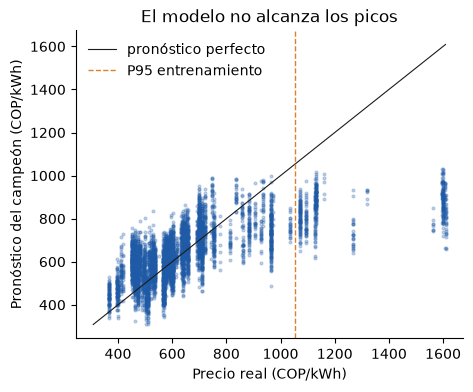

In [5]:
price = hourly['precio_bolsa']
volatility = price.rolling(24, min_periods=24).std()
frame['volatilidad_24h'] = frame['fecha_objetivo'].map(volatility)
vol_threshold = frame.drop_duplicates('fecha_objetivo')['volatilidad_24h'].quantile(0.75)
spike_threshold = train['precio_bolsa'].quantile(0.95)
frame['alta_volatilidad'] = frame['volatilidad_24h'] >= vol_threshold
frame['evento_extremo'] = frame['real'] >= spike_threshold

print(f'Umbral de volatilidad (σ 24 h): {vol_threshold:,.0f} COP/kWh')
print(f'Umbral de evento extremo (P95 entrenamiento): {spike_threshold:,.0f} COP/kWh')
display(regime_table(frame, 'alta_volatilidad').rename_axis('alta volatilidad'))
display(regime_table(frame, 'evento_extremo').rename_axis('evento extremo'))
spikes = frame[frame['evento_extremo']]
print(f"Pronóstico máximo del campeón: {frame['champion'].max():,.0f} | "
      f"precio real máximo: {frame['real'].max():,.0f} COP/kWh")
print(f"Eventos extremos subestimados: {(spikes['error'] < 0).mean():.0%}")

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(frame['real'], frame['champion'], s=4, alpha=0.25, color='#1f5aa6')
lims = [frame[['real', 'champion']].min().min(), frame[['real', 'champion']].max().max()]
ax.plot(lims, lims, color='#1b1b1b', lw=0.8, label='pronóstico perfecto')
ax.axvline(spike_threshold, color='#d9822b', ls='--', lw=1, label='P95 entrenamiento')
ax.set_xlabel('Precio real (COP/kWh)')
ax.set_ylabel('Pronóstico del campeón (COP/kWh)')
ax.set_title('El modelo no alcanza los picos')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
export(fig, 'real_vs_pronostico_dispersion')

## 5. Resumen de condiciones

In [6]:
conditions = {
    'horas de punta': frame['regimen'] == 'punta',
    'horas valle': frame['regimen'] == 'valle',
    'baja hidrología': frame['baja_hidrologia'],
    'alta participación térmica': frame['alta_termica'],
    'alta volatilidad': frame['alta_volatilidad'],
    'evento extremo': frame['evento_extremo'],
}
rows = []
for name, mask in conditions.items():
    subset = frame[mask]
    rows.append({
        'condición': name,
        'fracción de horas': mask.mean(),
        'fracción del error': subset['abs'].sum() / frame['abs'].sum(),
        'MAE campeón': subset['abs'].mean(),
        'MAE persistencia 24 h': subset['abs_naive'].mean(),
        'sesgo campeón': subset['error'].mean(),
    })
overview = pd.DataFrame(rows).set_index('condición')
overview.to_csv(metrics_dir / 'postmortem_condiciones.csv', float_format='%.4f')
display(overview.style.format({
    'fracción de horas': '{:.1%}', 'fracción del error': '{:.1%}',
    'MAE campeón': '{:,.1f}', 'MAE persistencia 24 h': '{:,.1f}', 'sesgo campeón': '{:,.1f}',
}))

,fracción de horas,fracción del error,MAE campeón,MAE persistencia 24 h,sesgo campeón
condición,,,,,
horas de punta,16.7%,38.4%,259.0,178.6,-225.0
horas valle,25.0%,15.1%,67.9,46.0,39.8
baja hidrología,90.4%,91.2%,113.5,111.4,-26.7
alta participación térmica,100.0%,100.0%,112.5,106.4,-23.1
alta volatilidad,24.7%,34.0%,155.0,125.2,-111.2
evento extremo,8.5%,33.3%,442.8,211.1,-442.8


## 6. Hallazgos y acciones

Cifras sobre 249 ventanas de prueba (pronósticos del 19 al 30 de septiembre de 2026, 5 976 parejas ventana-hora) con el campeón TCN.

1. **Los picos concentran el error.** Las horas con precio por encima del P95 de entrenamiento (≈ 1 050 COP/kWh) son el 8 % de las horas pero explican un tercio del error absoluto. En ellas el MAE del campeón (≈ 443) duplica al de la persistencia (≈ 211) y el error es siempre una subestimación: el pronóstico máximo del modelo (≈ 1 030) nunca llega a los valores cercanos a 1 600 COP/kWh que se repiten en la serie real. La pérdida de Huber y la regresión hacia la media suavizan los picos.
2. **Las horas de punta (18–21 h) son el punto débil.** Ocupan el 17 % de las horas y aportan el 38 % del error; allí la persistencia de 24 h gana con claridad (≈ 179 frente a ≈ 259). En la madrugada (valle) también gana la persistencia, porque el precio nocturno es casi plano y repetirlo es difícil de batir.
3. **En horas intermedias el modelo sí aporta.** Ahí está el 58 % de las horas y el campeón reduce el MAE frente a la persistencia (≈ 90 frente a ≈ 112). En todo el periodo, además, acierta más la dirección del precio hora a hora (69 % frente a 56 %).
4. **El periodo de prueba es más seco que el de entrenamiento.** Cerca del 90 % de las horas evaluadas tienen aportes por debajo del P25 de entrenamiento, y todas tienen una participación térmica por encima de su P75. No hay suficientes horas en condiciones normales para contrastar regímenes hidrológicos dentro de la prueba; lo que sí muestra es un cambio de régimen respecto al entrenamiento. Dentro de la prueba, al pasar de horas normales a secas el MAE de la persistencia casi se duplica (≈ 59 → ≈ 111) mientras el del campeón sube poco (≈ 103 → ≈ 114); aun así, en las horas secas ambos quedan parejos.

**Acciones sugeridas** (para validar en el conjunto de *validación*, no en este):

- Entrenar con **pérdida cuantílica** (ya soportada en `config.models.loss`) para obtener un cuantil alto que anticipe los picos y dé intervalos al dashboard del Sprint 5.
- Probar un **modelo híbrido**: persistencia en horas de punta y valle, campeón en horas intermedias. Debe elegirse con validación para no sobreajustar a la prueba.
- **Ampliar la historia** (`data.window`) para incluir periodos secos y de escasez anteriores; con cuatro meses el modelo vio muy pocos picos.
- Revisar la escala de `precio_bolsa_diff_1`: domina las atribuciones de gradientes integrados porque su rango intercuartílico de entrenamiento es pequeño (el precio suele quedarse fijo de una hora a otra) y los saltos quedan muy amplificados tras el escalado.